# UJIAN TENGAH SEMESTER (UTS) PRAKTIKUM
## Mata Kuliah   : 4233201 – Kecerdasan Buatan
## Semester      : Gasal T.A. 2025/2026
## Hari, Tanggal : Selasa, 14 Oktober 2025
## Nama          : Oktova Yoga Praditia Samosir
## NIM           : 42324001 (NIM Ganjil -> Wajib Mengerjakan Soal 3 NIM Ganjil)
## Program Studi : D3 Teknologi Informasi
## Dosen Pengampu: Tegar Arifin Prasetyo / Rudy Chandra
## Institusi     : Institut Teknologi Del

---

### PETUNJUK PENGERJAAN:
1. Ujian bersifat terbuka (*open source*) menggunakan modul praktikum dan referensi materi.
2. Setiap kode program disertai penjelasan fungsi, alur logika, dan interpretasi output secara lengkap.
3. Seluruh hasil running code ditampilkan langsung di dalam Jupyter Notebook ini.
4. Pengerjaan mencakup:
   - **Soal 1 [30 Poin]**: Dataset `users_data_cleaned.pickle` (13 instruksi analisis eksplorasi & visualisasi data).
   - **Soal 2 [35 Poin]**: Dataset `Sales_Data.csv` (Prediksi Nilai Penjualan berdasarkan Biaya Promosi dengan Regresi Linier, Intercept, Slope, $R^2$, dan Visualisasi).
   - **Soal 3 (NIM Ganjil) [35 Poin]**: Dataset `pima-indians-diabetes.data.csv` (Klasifikasi Diabetes menggunakan K-NN, Split 85:15, K=5 Euclidean, Akurasi, dan Grafik Akurasi K=1..10).
   - **Soal 3 (NIM Genap) [Bonus Tambahan]**: Dataset `konsumen.csv` (Klasterisasi Gaji dan Pengeluaran dengan K-Means 2 klaster dan visualisasi titik pusat klaster).


In [1]:
# Import library dasar yang dibutuhkan untuk manipulasi data, komputasi numerik, dan visualisasi
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Compatibility Patch untuk pembacaan users_data_cleaned.pickle di versi Pandas terbaru (Pandas 2.x+)
# File pickle yang dibuat dengan pandas versi 1.x mereferensikan pandas.core.indexes.numeric yang telah diintegrasikan ke Base Index
import pandas.core.indexes.base as base
base.Int64Index = pd.Index
base.Float64Index = pd.Index
sys.modules['pandas.core.indexes.numeric'] = base

# Konfigurasi visualisasi grafik
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Setup environment dan library berhasil diinisialisasi dengan sempurna!")


Setup environment dan library berhasil diinisialisasi dengan sempurna!


### Penjelasan:
Sel di atas memuat library utama yang dibutuhkan dalam pengerjaan praktikum:
- `numpy`: Untuk komputasi array multidimensi dan operasi numerik matematis.
- `pandas`: Untuk manipulasi dan analisis data berbentuk tabel / DataFrame.
- `matplotlib.pyplot` & `seaborn`: Untuk pembuatan visualisasi statistik (histogram, boxplot, lineplot, scatter plot, bar chart, dan heatmap).
- **Compatibility Patch**: Menangani kompatibilitas pembacaan objek serialisasi `pickle` lama pada Pandas versi modern (`pandas.core.indexes.numeric.Int64Index`).

---
# SOAL 1 [30 poin]
Diberikan dataset `users_data_cleaned.pickle`. Dikerjakan sesuai 13 instruksi:
1. Load and preview the data
2. Check the shape of the data
3. Check the data types
4. Check for correlations
5. Generate summary statistics for numerical data only
6. Plot Histograms for all numerical columns
7. Generate a box plot for `age`, dan `number_transactions`
8. Generate a lineplot for `date_joined` to `total_amount_usd`
9. Generate scatter plots comparing `total_amount_usd` to `number_transaction`
10. Generate Horizontal bar charts for `job`
11. Generate Horizontal bar charts for `marital`
12. Generate a heatmap for future correlations
13. Identify Missing Values


In [2]:
# 1. Load and preview the data
# Membaca dataset format pickle ke dalam DataFrame
df_users = pd.read_pickle('users_data_cleaned.pickle')

# Menampilkan 5 baris pertama data
print("=== 5 Baris Pertama users_data_cleaned.pickle ===")
display(df_users.head())


=== 5 Baris Pertama users_data_cleaned.pickle ===


,user_id,number_transactions,total_amount_usd,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,term_deposit,date_joined,device
0,9231c446-cb16-4b2b-a7f7-ddfc8b25aaf6,3.0,2143.0,58,management,married,tertiary,False,True,False,None,261,1,-1,0,None,False,1998-08-23,mobile
1,bb92765a-08de-4963-b432-496524b39157,NaN,NaN,44,technician,single,secondary,False,True,False,None,151,1,-1,0,None,False,2008-07-15,desktop
2,573de577-49ef-42b9-83da-d3cfb817b5c1,2.0,2.0,33,entrepreneur,married,secondary,False,True,True,None,76,1,-1,0,None,False,2002-06-04,mobile
3,d6b66b9d-7c8f-4257-a682-e136f640b7e3,NaN,NaN,47,blue-collar,married,None,False,True,False,None,92,1,-1,0,None,False,1995-06-29,tablet
4,fade0b20-7594-4d9a-84cd-c02f79b1b526,1.0,1.0,33,None,single,None,False,False,False,None,198,1,-1,0,None,False,1995-08-01,mobile


### Penjelasan (Langkah 1):
Fungsi `pd.read_pickle('users_data_cleaned.pickle')` digunakan untuk memuat data pengguna perbankan/platform yang telah dibersihkan ke dalam variabel DataFrame `df_users`. Perintah `df_users.head()` menampilkan 5 baris pertama untuk memberikan gambaran umum mengenai fitur-fitur yang ada.

In [3]:
# 2. Check the shape of the data
shape_data = df_users.shape
print(f"Bentuk (Shape) Dataset: {shape_data}")
print(f"- Jumlah Baris (Observasi): {shape_data[0]:,} baris")
print(f"- Jumlah Kolom (Fitur)    : {shape_data[1]} kolom")


Bentuk (Shape) Dataset: (45209, 19)
- Jumlah Baris (Observasi): 45,209 baris
- Jumlah Kolom (Fitur)    : 19 kolom


### Penjelasan (Langkah 2):
Atribut `df_users.shape` mengembalikan sebuah tuple yang merepresentasikan dimensi matriks data. Dari hasil di atas, dataset memiliki **45.209 baris data** dan **19 kolom atribut**.

In [4]:
# 3. Check the data types
print("=== Tipe Data Setiap Kolom pada users_data_cleaned ===")
df_types = pd.DataFrame({
    'Nama Kolom': df_users.columns,
    'Tipe Data': df_users.dtypes.values
})
display(df_types)


=== Tipe Data Setiap Kolom pada users_data_cleaned ===


,Nama Kolom,Tipe Data
0,user_id,object
1,number_transactions,float64
2,total_amount_usd,float64
3,age,int64
4,job,object
5,marital,object
6,education,object
7,default,bool
8,housing,bool
9,loan,bool


### Penjelasan (Langkah 3):
Atribut `df_users.dtypes` memeriksa tipe data dari masing-masing kolom. Dataset terdiri dari kombinasi kolom bertipe numerik desimal (`float64`), numerik bulat (`int64`), kategorikal teks (`object`), boolean (`bool`), dan tanggal waktu (`datetime64[ns]`).

In [5]:
# 4. Check for correlations
# Menghitung korelasi antar variabel numerik menggunakan metode Pearson
numeric_data = df_users.select_dtypes(include=[np.number])
correlation_matrix = numeric_data.corr()

print("=== Matriks Korelasi Antar Kolom Numerik ===")
display(correlation_matrix.round(4))


=== Matriks Korelasi Antar Kolom Numerik ===


,number_transactions,total_amount_usd,age,duration,campaign,pdays,previous
number_transactions,1.0000,-0.1634,-0.0088,-0.0172,0.0264,-0.0308,-0.0230
total_amount_usd,-0.1634,1.0000,0.0958,0.0226,-0.0173,0.0064,0.0170
age,-0.0088,0.0958,1.0000,-0.0046,0.0048,-0.0237,0.0013
duration,-0.0172,0.0226,-0.0046,1.0000,-0.0846,-0.0015,0.0012
campaign,0.0264,-0.0173,0.0048,-0.0846,1.0000,-0.0886,-0.0329
pdays,-0.0308,0.0064,-0.0237,-0.0015,-0.0886,1.0000,0.4548
previous,-0.0230,0.0170,0.0013,0.0012,-0.0329,0.4548,1.0000


### Penjelasan (Langkah 4):
Fungsi `.corr()` pada subset kolom numerik menghitung koefisien korelasi Pearson antar variabel (rentang -1 hingga +1). Terlihat bahwa korelasi antar variabel umumnya lemah, kecuali `previous` dan `pdays` yang memiliki hubungan linier positif moderate (~0.45).

In [6]:
# 5. Generate summary statistics for numerical data only
print("=== Ringkasan Statistik Deskriptif untuk Data Numerik ===")
display(numeric_data.describe().round(2))


=== Ringkasan Statistik Deskriptif untuk Data Numerik ===


,number_transactions,total_amount_usd,age,duration,campaign,pdays,previous
count,35210.00,35210.00,45209.00,45209.00,45209.00,45209.00,45209.00
mean,3.98,1369.42,40.94,258.15,2.76,40.20,0.58
std,3.81,3063.41,10.62,257.53,3.10,100.13,2.30
min,1.00,-8019.00,18.00,0.00,1.00,-1.00,0.00
25%,2.00,73.00,33.00,103.00,1.00,-1.00,0.00
50%,3.00,451.00,39.00,180.00,2.00,-1.00,0.00
75%,4.00,1438.00,48.00,319.00,3.00,-1.00,0.00
max,20.00,102127.00,95.00,4918.00,63.00,871.00,275.00


### Penjelasan (Langkah 5):
Fungsi `numeric_data.describe()` menyajikan ringkasan statistik deskriptif untuk fitur numerik, mencakup: jumlah data (*count*), rata-rata (*mean*), standar deviasi (*std*), nilai minimum (*min*), kuartil bawah (*25%*), median (*50%*), kuartil atas (*75%*), dan nilai maksimum (*max*).

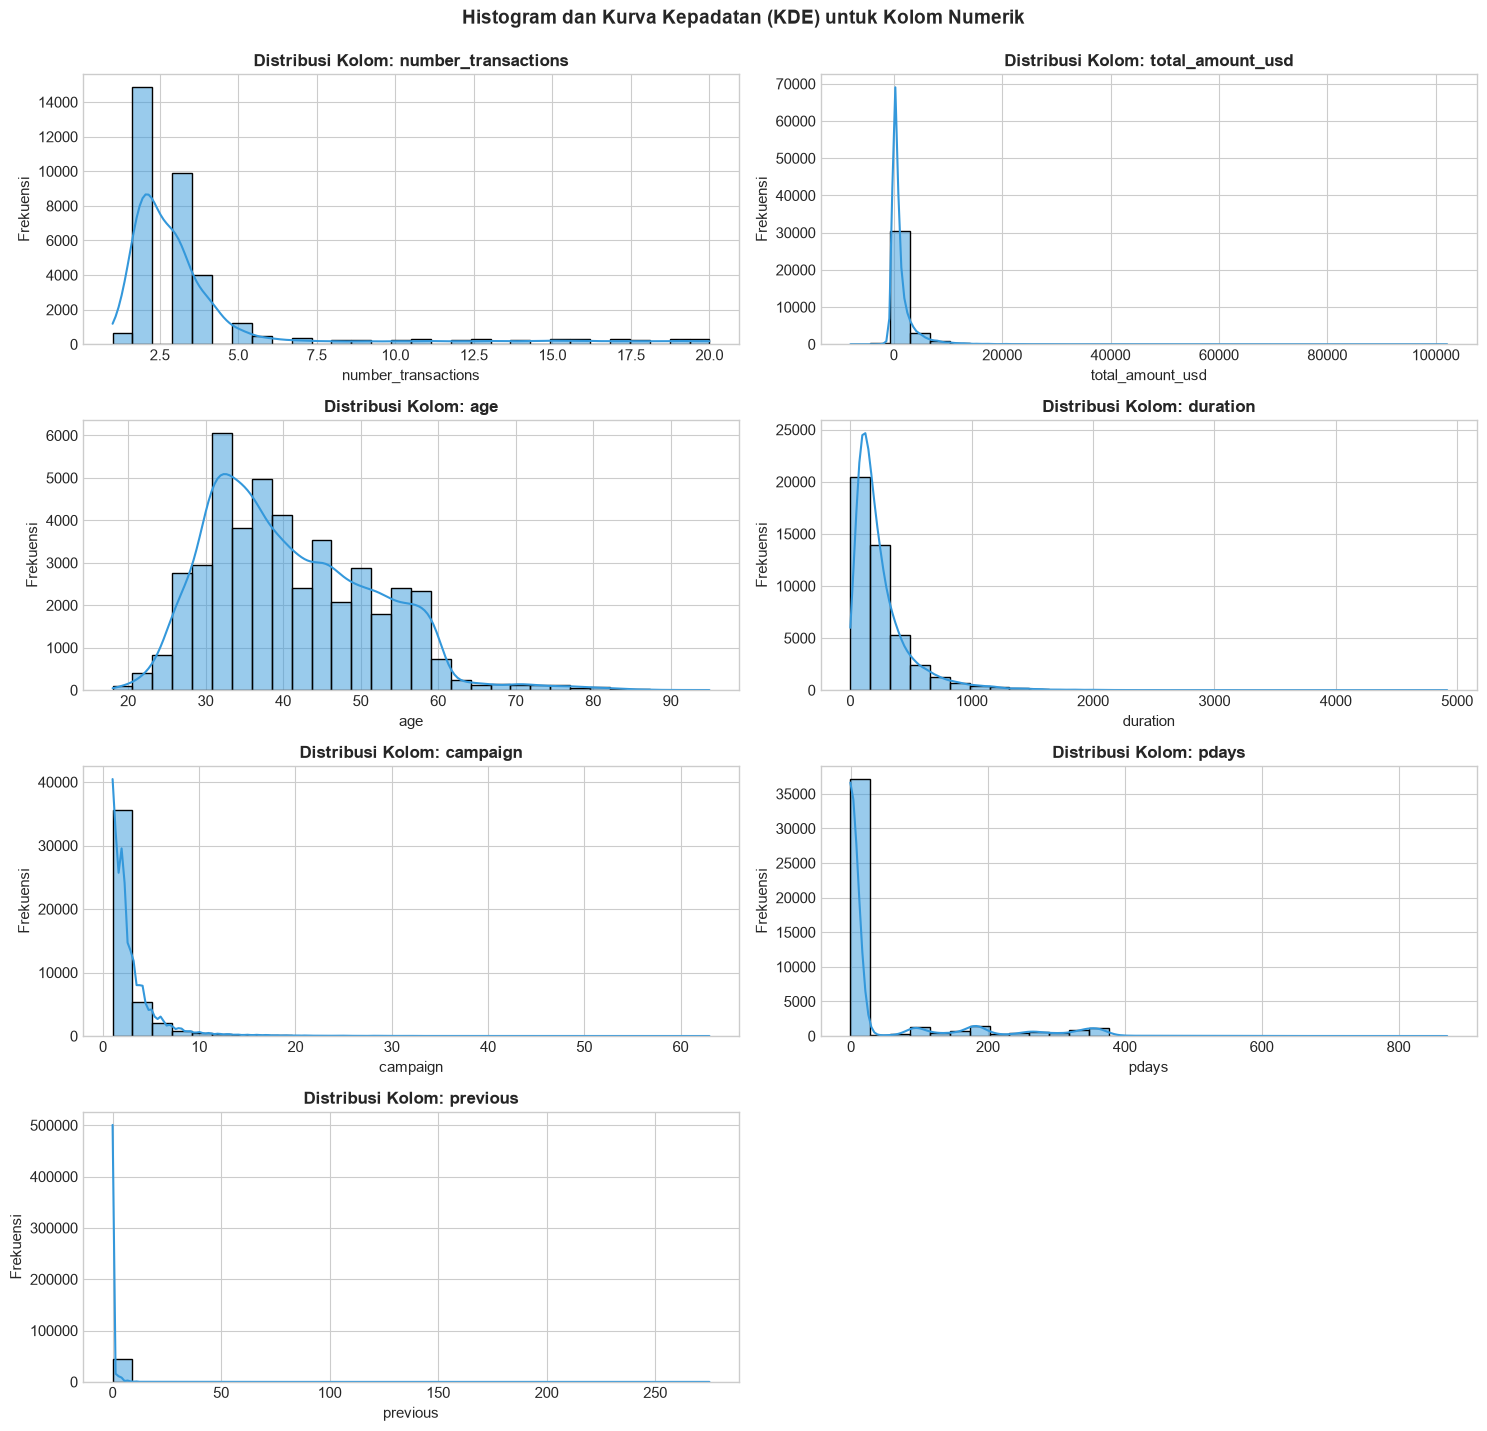

In [7]:
# 6. Plot Histograms for all numerical columns
fig, axes = plt.subplots(4, 2, figsize=(15, 14))
axes = axes.flatten()

num_columns = numeric_data.columns.tolist()

for i, col in enumerate(num_columns):
    sns.histplot(df_users[col].dropna(), kde=True, ax=axes[i], color='#3498db', bins=30, edgecolor='black')
    axes[i].set_title(f'Distribusi Kolom: {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frekuensi')

# Menghapus sumbu kosong ke-8 karena hanya ada 7 kolom numerik
if len(num_columns) < len(axes):
    fig.delaxes(axes[-1])

plt.tight_layout()
plt.suptitle('Histogram dan Kurva Kepadatan (KDE) untuk Kolom Numerik', fontsize=14, y=1.02, fontweight='bold')
plt.show()


### Penjelasan (Langkah 6):
Visualisasi histogram menggunakan `sns.histplot` dengan kurva KDE (*Kernel Density Estimation*) menunjukkan bentuk distribusi frekuensi tiap fitur numerik. Fitur `age` memiliki kurva mendekati normal dengan puncak pada usia 30-40 tahun, sedangkan `total_amount_usd` dan `number_transactions` memiliki sebaran yang *right-skewed*.

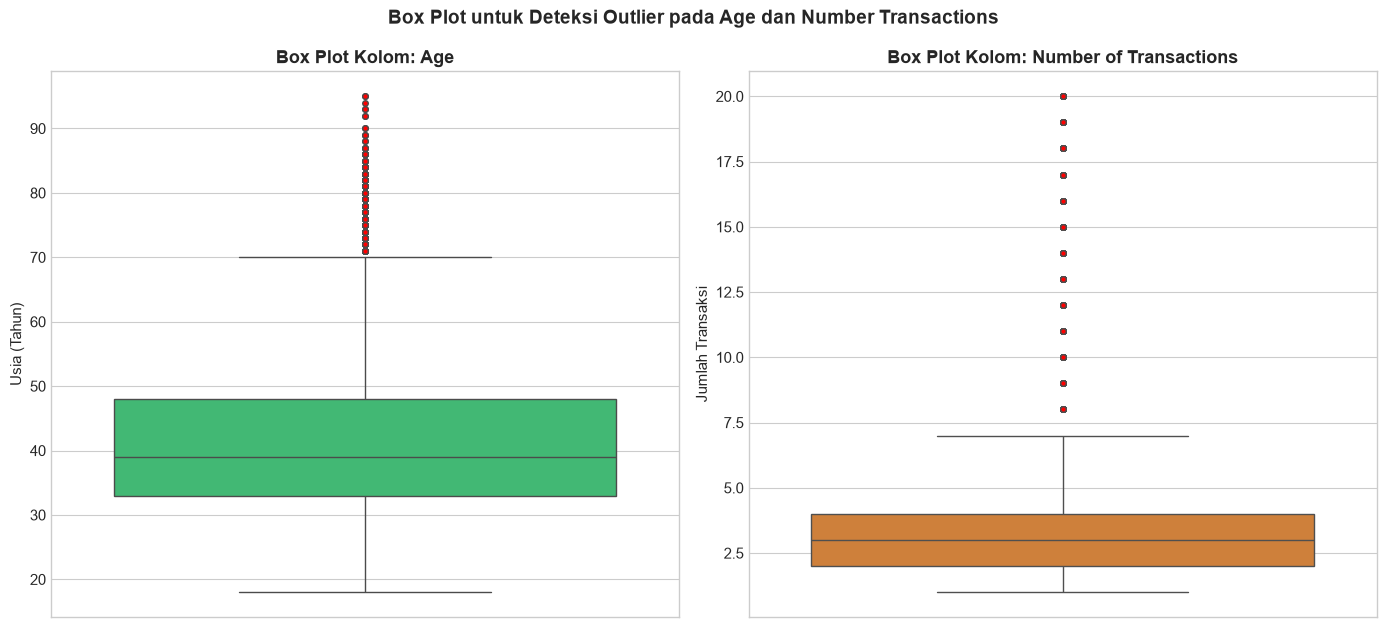

In [8]:
# 7. Generate a box plot for age, dan number_transactions
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Boxplot untuk age
sns.boxplot(y=df_users['age'], ax=axes[0], color='#2ecc71', flierprops={'markerfacecolor': 'red', 'markersize': 4})
axes[0].set_title('Box Plot Kolom: Age', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Usia (Tahun)')

# Boxplot untuk number_transactions
sns.boxplot(y=df_users['number_transactions'].dropna(), ax=axes[1], color='#e67e22', flierprops={'markerfacecolor': 'red', 'markersize': 4})
axes[1].set_title('Box Plot Kolom: Number of Transactions', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Jumlah Transaksi')

plt.tight_layout()
plt.suptitle('Box Plot untuk Deteksi Outlier pada Age dan Number Transactions', fontsize=14, y=1.04, fontweight='bold')
plt.show()


### Penjelasan (Langkah 7):
Box plot dibuat untuk memeriksa sebaran nilai kuartil (Q1, median, Q3) serta deteksi outlier pada `age` dan `number_transactions`. Titik-titik merah di luar garis kumis (*whisker*) mengindikasikan adanya nilai pencilan/ekstrem.

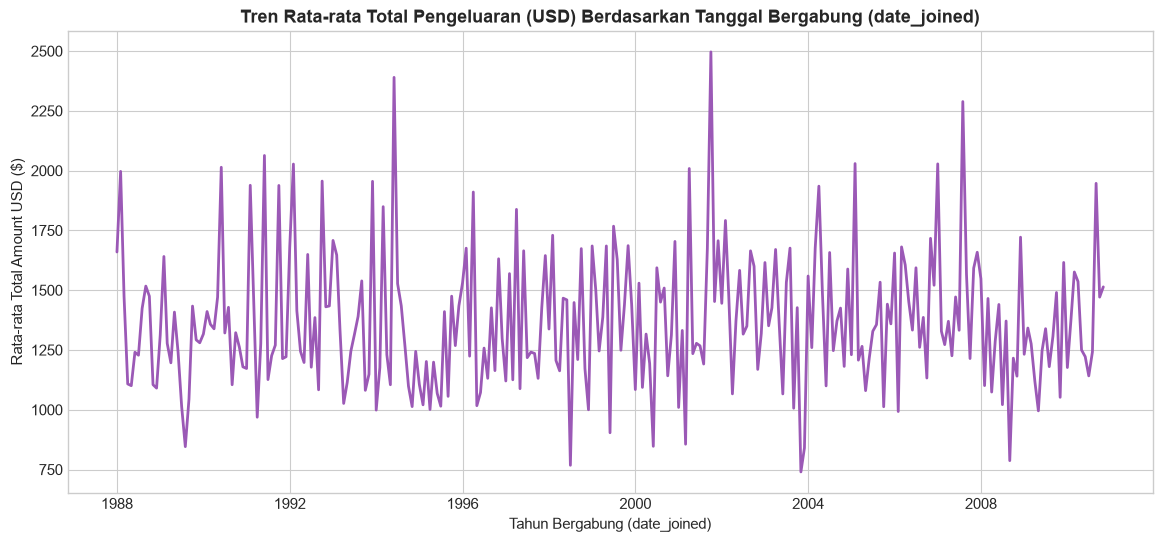

In [9]:
# 8. Generate a lineplot for date_joined to total_amount_usd
# Menyiapkan data bebas nilai kosong untuk date_joined dan total_amount_usd
df_line_data = df_users.dropna(subset=['date_joined', 'total_amount_usd']).copy()

# Melakukan agregasi rata-rata transaksi per bulan agar grafik tren waktu terbaca informatif dan jelas
df_line_data['YearMonth'] = df_line_data['date_joined'].dt.to_period('M').dt.to_timestamp()
monthly_avg_spending = df_line_data.groupby('YearMonth')['total_amount_usd'].mean().reset_index()

plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_avg_spending, x='YearMonth', y='total_amount_usd', color='#9b59b6', linewidth=2)
plt.title('Tren Rata-rata Total Pengeluaran (USD) Berdasarkan Tanggal Bergabung (date_joined)', fontsize=13, fontweight='bold')
plt.xlabel('Tahun Bergabung (date_joined)', fontsize=11)
plt.ylabel('Rata-rata Total Amount USD ($)', fontsize=11)
plt.grid(True)
plt.show()


### Penjelasan (Langkah 8):
Line plot menghubungkan variabel waktu `date_joined` dengan variabel kontinu `total_amount_usd`. Agregasi tren bulanan menunjukkan fluktuasi rata-rata nilai transaksi pengguna sepanjang tahun keanggotaan.

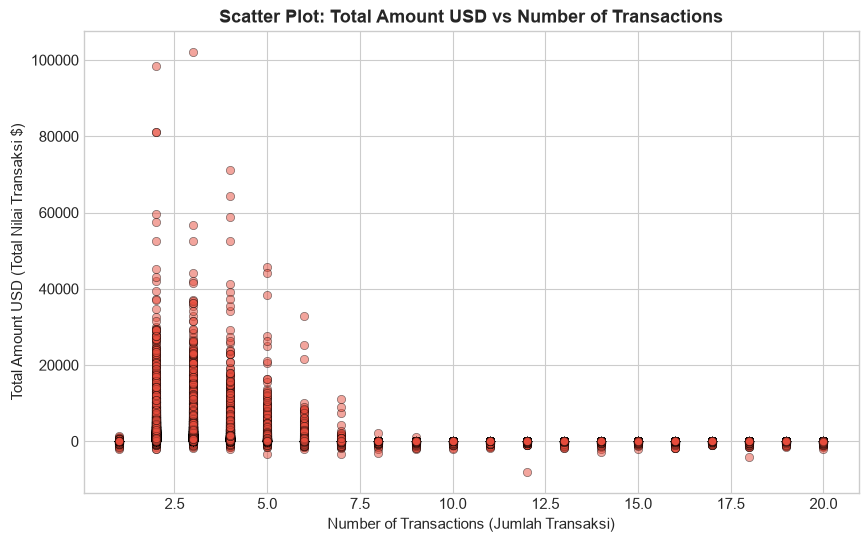

In [10]:
# 9. Generate scatter plots comparing total_amount_usd to number_transaction
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_users.dropna(subset=['total_amount_usd', 'number_transactions']),
    x='number_transactions',
    y='total_amount_usd',
    alpha=0.5,
    color='#e74c3c',
    edgecolor='black',
    linewidth=0.5
)
plt.title('Scatter Plot: Total Amount USD vs Number of Transactions', fontsize=13, fontweight='bold')
plt.xlabel('Number of Transactions (Jumlah Transaksi)', fontsize=11)
plt.ylabel('Total Amount USD (Total Nilai Transaksi $)', fontsize=11)
plt.grid(True)
plt.show()


### Penjelasan (Langkah 9):
Scatter plot memetakan hubungan bivariat antara frekuensi transaksi (`number_transactions`) dan total pengeluaran moneter (`total_amount_usd`). Terlihat bahwa sebagian besar pengguna terkonsentrasi pada transaksi di bawah 10 kali dengan total belanja di bawah $20.000.

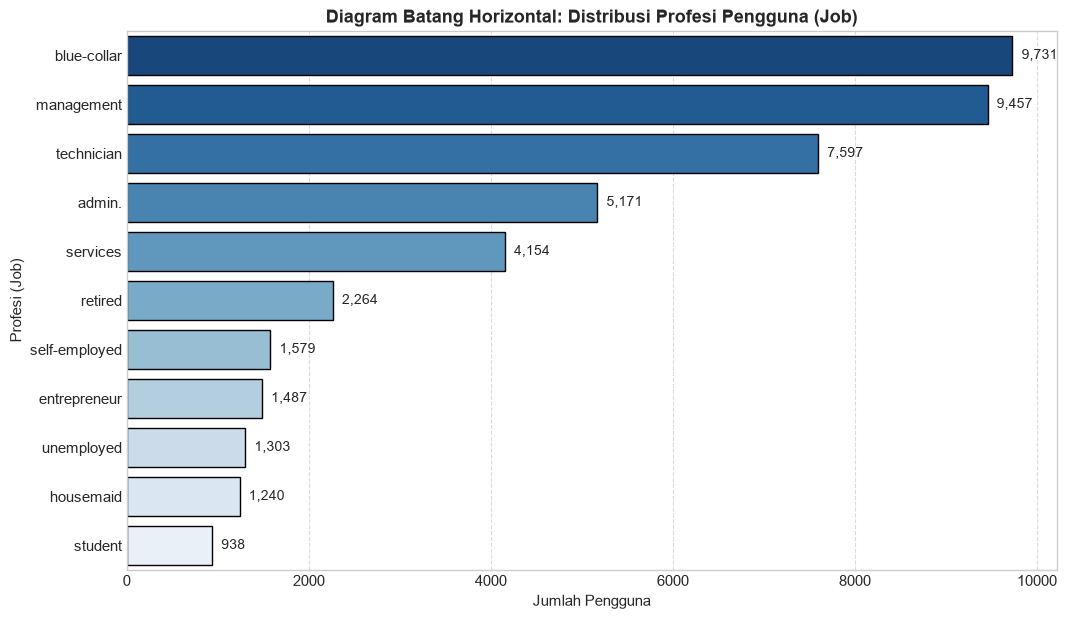

In [11]:
# 10. Generate Horizontal bar charts for job
plt.figure(figsize=(12, 7))
job_counts = df_users['job'].value_counts()
sns.barplot(y=job_counts.index, x=job_counts.values, palette='Blues_r', edgecolor='black')
plt.title('Diagram Batang Horizontal: Distribusi Profesi Pengguna (Job)', fontsize=13, fontweight='bold')
plt.xlabel('Jumlah Pengguna', fontsize=11)
plt.ylabel('Profesi (Job)', fontsize=11)

# Menambahkan label angka di setiap bar
for index, value in enumerate(job_counts.values):
    plt.text(value + 100, index, f"{value:,}", va='center', fontsize=10)

plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()


### Penjelasan (Langkah 10):
Diagram batang horizontal menampilkan kategori pekerjaan (`job`) yang diurutkan dari frekuensi terbanyak. Tiga profesi teratas adalah *blue-collar* (9.731), *management* (9.457), dan *technician* (7.597).

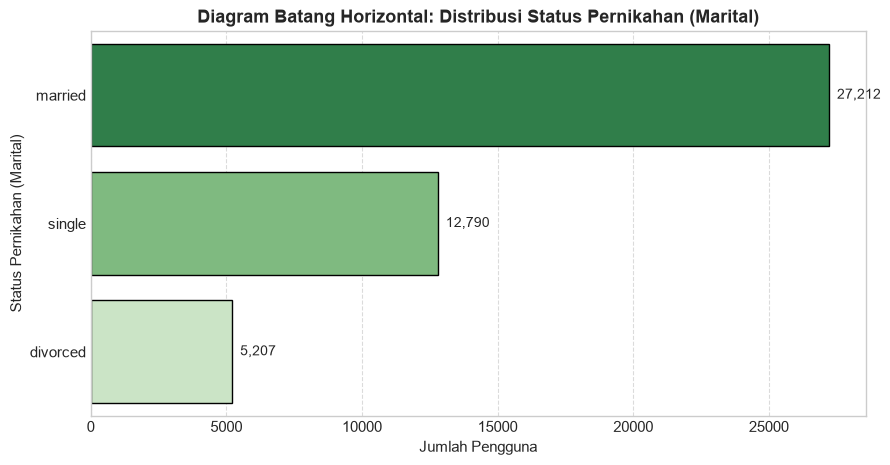

In [12]:
# 11. Generate Horizontal bar charts for marital
plt.figure(figsize=(10, 5))
marital_counts = df_users['marital'].value_counts()
sns.barplot(y=marital_counts.index, x=marital_counts.values, palette='Greens_r', edgecolor='black')
plt.title('Diagram Batang Horizontal: Distribusi Status Pernikahan (Marital)', fontsize=13, fontweight='bold')
plt.xlabel('Jumlah Pengguna', fontsize=11)
plt.ylabel('Status Pernikahan (Marital)', fontsize=11)

# Menambahkan label angka di setiap bar
for index, value in enumerate(marital_counts.values):
    plt.text(value + 300, index, f"{value:,}", va='center', fontsize=10)

plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()


### Penjelasan (Langkah 11):
Diagram batang horizontal untuk kolom `marital` menunjukkan status pernikahan pengguna didominasi oleh kategori *married* (27.212 orang), diikuti *single* (12.790 orang), dan *divorced* (5.207 orang).

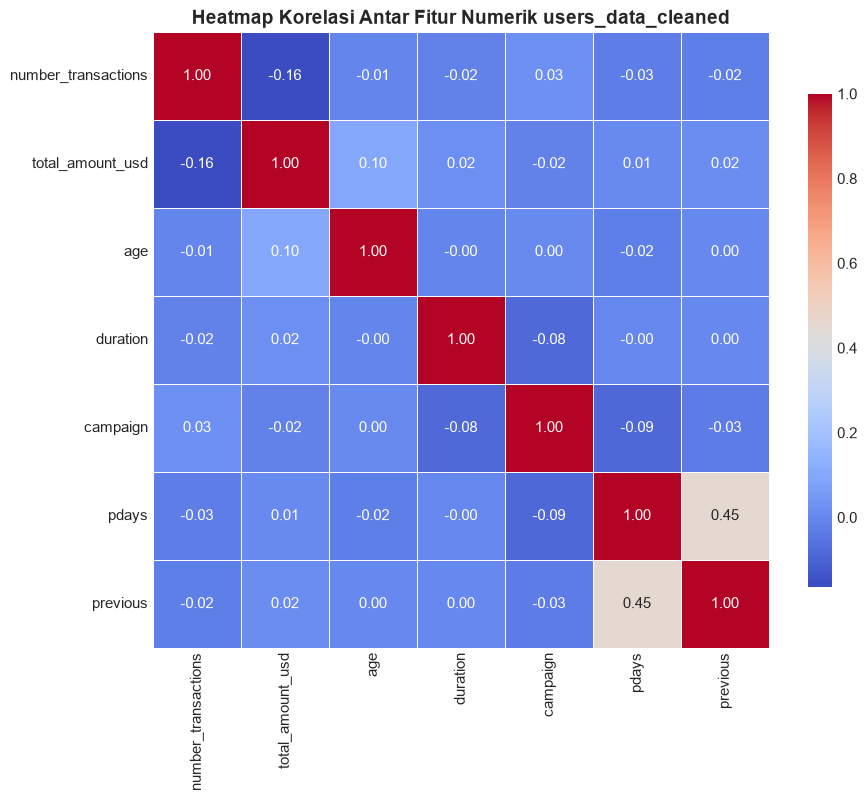

In [13]:
# 12. Generate a heatmap for future correlations
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool)) # Matriks segitiga atas opsional
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    square=True,
    cbar_kws={'shrink': 0.8}
)
plt.title('Heatmap Korelasi Antar Fitur Numerik users_data_cleaned', fontsize=14, fontweight='bold')
plt.show()


### Penjelasan (Langkah 12):
Heatmap korelasi memvisualisasikan derajat kekuatan hubungan linier antar variabel dengan gradasi warna (*coolwarm*). Nilai mendekati +1 (merah) menunjukkan korelasi positif kuat, sedangkan nilai mendekati -1 (biru) menunjukkan korelasi negatif.

In [14]:
# 13. Identify Missing Values
missing_count = df_users.isnull().sum()
missing_percent = (100 * df_users.isnull().mean()).round(2)

df_missing_report = pd.DataFrame({
    'Jumlah Missing': missing_count,
    'Persentase Missing (%)': missing_percent
})

# Menampilkan kolom yang memiliki missing value
print("=== Kolom yang Memiliki Missing Value pada users_data_cleaned ===")
display(df_missing_report[df_missing_report['Jumlah Missing'] > 0].sort_values(by='Jumlah Missing', ascending=False))


=== Kolom yang Memiliki Missing Value pada users_data_cleaned ===


,Jumlah Missing,Persentase Missing (%)
poutcome,36957,81.75
contact,13018,28.80
number_transactions,9999,22.12
total_amount_usd,9999,22.12
education,1857,4.11
job,288,0.64
device,94,0.21
date_joined,30,0.07


### Penjelasan (Langkah 13):
Identifikasi missing values menggunakan `df_users.isnull().sum()` menemukan bahwa terdapat 8 kolom yang memuat data kosong. Persentase tertinggi berada pada kolom `poutcome` (81.75%), `contact` (28.79%), serta `number_transactions` dan `total_amount_usd` (masing-masing 22.12%).

---
# SOAL 2 [35 poin]
Diberikan dataset `Sales_Data.csv` yang berisikan informasi berupa **Biaya Promo** dan **Nilai Penjualan**. Dibuat model untuk memprediksi nilai penjualan berdasarkan biaya promosi menggunakan algoritma **LinearRegression**.

Komponen Penilaian:
1. **Screenshot code dan output**:
   - a. Membaca file `Sales_Data.csv`
   - b. Menampilkan variable dalam dataset
   - c. Menampilkan data yang di-split (train: 80% & test: 20%)
   - d. Memanggil `LinearRegression()`
   - e. Menampilkan hasil `predict` dari data test
   - f. Menampilkan Grafik Nilai Penjualan berdasarkan Biaya Promosi
   - g. Menampilkan Garis hasil prediksi dari machine learning pada Biaya Promosi terhadap penjualan (train set dan test set)
2. **Hitunglah**:
   - a. Intercept
   - b. Slope
   - c. R-Square


In [15]:
# 1.a & 1.b: Membaca file Sales_Data.csv dan Menampilkan Variabel dalam Dataset
# Catatan: Dataset menggunakan pemisah tanda titik-koma (sep=';')
df_sales = pd.read_csv('Sales_Data.csv', sep=';')

print("=== 5 Baris Pertama Sales_Data.csv ===")
display(df_sales.head())

print("\n=== Variabel dalam Dataset Sales_Data.csv ===")
print("Nama-nama Kolom:", df_sales.columns.tolist())
display(df_sales.info())


=== 5 Baris Pertama Sales_Data.csv ===


,BiayaPromo,NilaiPenjualan
0,1500,90500
1,1800,89500
2,1900,105000
3,2050,102000
4,2050,90500



=== Variabel dalam Dataset Sales_Data.csv ===
Nama-nama Kolom: ['BiayaPromo', 'NilaiPenjualan']
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   BiayaPromo      20 non-null     int64
 1   NilaiPenjualan  20 non-null     int64
dtypes: int64(2)
memory usage: 452.0 bytes


None

### Penjelasan (Soal 2 Poin 1.a & 1.b):
File `Sales_Data.csv` dibaca menggunakan parameter `sep=';'` karena kolom dipisahkan oleh tanda titik koma. Dataset terdiri dari 20 baris data dengan 2 variabel numerik:
- `BiayaPromo`: Biaya promosi yang dikeluarkan (variabel independen / $X$).
- `NilaiPenjualan`: Nilai total penjualan yang dihasilkan (variabel dependen / $y$).

In [16]:
# 1.c, 1.d, & 1.e: Split Data (80:20), Fitting LinearRegression, dan Hasil Predict
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Menentukan fitur X dan target y
X_sales = df_sales[['BiayaPromo']].values
y_sales = df_sales['NilaiPenjualan'].values

# 1.c Menampilkan data yang di-split (train: 80% & test: 20%)
X_train_sales, X_test_sales, y_train_sales, y_test_sales = train_test_split(
    X_sales, y_sales, test_size=0.20, random_state=42
)

print("=== Data yang Di-Split (Train 80% & Test 20%) ===")
print(f"Jumlah Data Latih (Train Set): {len(X_train_sales)} baris")
print(f"Jumlah Data Uji (Test Set)  : {len(X_test_sales)} baris")
print("\nData X_test (Biaya Promo):")
print(X_test_sales.flatten())
print("Data y_test aktual (Nilai Penjualan):")
print(y_test_sales)

# 1.d Memanggil LinearRegression() dan Melakukan Fitting Model
model_lr = LinearRegression()
model_lr.fit(X_train_sales, y_train_sales)

# 1.e Menampilkan Hasil Predict dari Data Test
y_pred_sales = model_lr.predict(X_test_sales)

df_hasil_prediksi = pd.DataFrame({
    'Biaya Promo (X_test)': X_test_sales.flatten(),
    'Penjualan Aktual (y_test)': y_test_sales,
    'Hasil Prediksi (y_pred)': y_pred_sales.round(2),
    'Selisih (Error)': (y_test_sales - y_pred_sales).round(2)
})

print("\n=== Tabel Hasil Prediksi Data Test ===")
display(df_hasil_prediksi)


=== Data yang Di-Split (Train 80% & Test 20%) ===
Jumlah Data Latih (Train Set): 16 baris
Jumlah Data Uji (Test Set)  : 4 baris

Data X_test (Biaya Promo):
[1500 4000 3900 1800]
Data y_test aktual (Nilai Penjualan):
[ 90500 170500 194500  89500]

=== Tabel Hasil Prediksi Data Test ===


,Biaya Promo (X_test),Penjualan Aktual (y_test),Hasil Prediksi (y_pred),Selisih (Error)
0,1500,90500,79244.65,11255.35
1,4000,170500,199104.61,-28604.61
2,3900,194500,194310.21,189.79
3,1800,89500,93627.85,-4127.85


### Penjelasan (Soal 2 Poin 1.c, 1.d, & 1.e):
Data dibagi 80% (16 baris) sebagai data latih dan 20% (4 baris) sebagai data uji menggunakan `train_test_split`. Objek `LinearRegression()` diinisialisasi dan dilatih menggunakan `.fit(X_train, y_train)`. Selanjutnya, model memprediksi nilai penjualan pada data uji menggunakan `.predict(X_test)`.

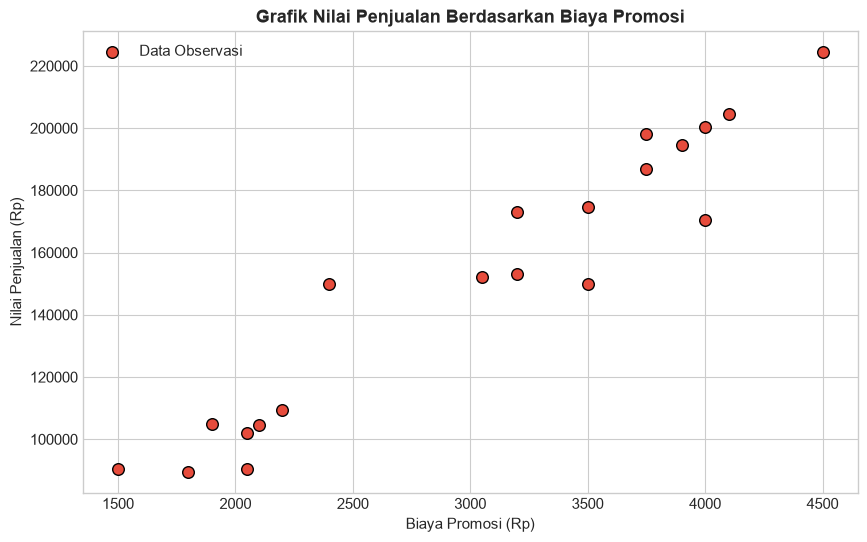

In [17]:
# 1.f: Menampilkan Grafik Nilai Penjualan berdasarkan Biaya Promosi
plt.figure(figsize=(10, 6))
plt.scatter(df_sales['BiayaPromo'], df_sales['NilaiPenjualan'], color='#e74c3c', s=70, edgecolor='black', label='Data Observasi')
plt.title('Grafik Nilai Penjualan Berdasarkan Biaya Promosi', fontsize=13, fontweight='bold')
plt.xlabel('Biaya Promosi (Rp)', fontsize=11)
plt.ylabel('Nilai Penjualan (Rp)', fontsize=11)
plt.grid(True)
plt.legend()
plt.show()


### Penjelasan (Soal 2 Poin 1.f):
Scatter plot di atas memetakan hubungan antara biaya promosi dan nilai penjualan. Pola titik data membentuk tren diagonal ke kanan atas, mengindikasikan adanya hubungan linier positif yang sangat kuat.

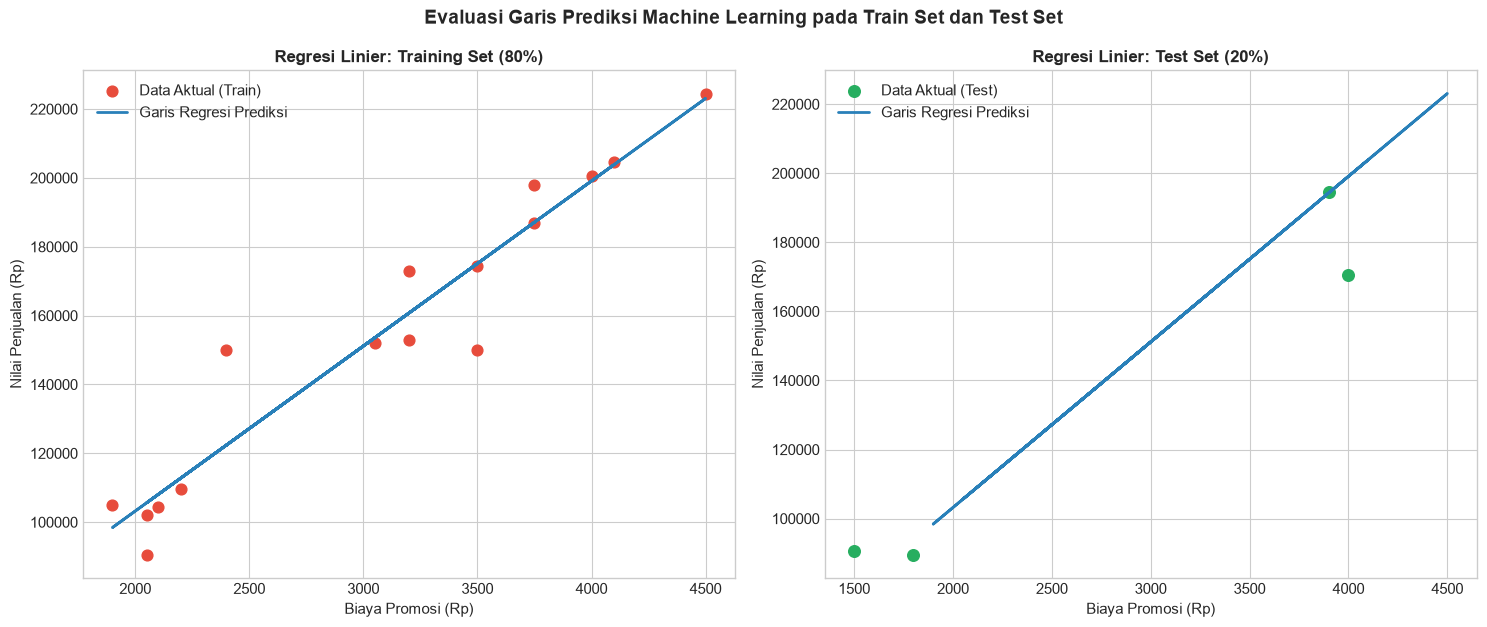

In [18]:
# 1.g: Menampilkan Garis Hasil Prediksi Machine Learning pada Biaya Promosi terhadap Penjualan
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Plot Garis Regresi pada Training Set
ax1.scatter(X_train_sales, y_train_sales, color='#e74c3c', s=60, label='Data Aktual (Train)')
ax1.plot(X_train_sales, model_lr.predict(X_train_sales), color='#2980b9', linewidth=2, label='Garis Regresi Prediksi')
ax1.set_title('Regresi Linier: Training Set (80%)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Biaya Promosi (Rp)')
ax1.set_ylabel('Nilai Penjualan (Rp)')
ax1.grid(True)
ax1.legend()

# Plot Garis Regresi pada Test Set
ax2.scatter(X_test_sales, y_test_sales, color='#27ae60', s=70, label='Data Aktual (Test)')
ax2.plot(X_train_sales, model_lr.predict(X_train_sales), color='#2980b9', linewidth=2, label='Garis Regresi Prediksi')
ax2.set_title('Regresi Linier: Test Set (20%)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Biaya Promosi (Rp)')
ax2.set_ylabel('Nilai Penjualan (Rp)')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.suptitle('Evaluasi Garis Prediksi Machine Learning pada Train Set dan Test Set', fontsize=14, y=1.04, fontweight='bold')
plt.show()


### Penjelasan (Soal 2 Poin 1.g):
Garis biru menggambarkan model regresi linier $\hat{y} = eta_0 + eta_1 X$. Titik data aktual pada training set (merah) dan test set (hijau) berada sangat dekat di sekitar garis prediksi, menandakan model memiliki tingkat kesesuaian (*goodness of fit*) yang sangat baik.

In [19]:
# 2. Hitunglah: Intercept, Slope, dan R-Square
intercept_val = model_lr.intercept_
slope_val = model_lr.coef_[0]
r2_val = r2_score(y_test_sales, y_pred_sales)

print("=== HASIL PERHITUNGAN PARAMETER REGRESI LINIER ===")
print(f"a. Intercept (Konstanta a / beta_0) : {intercept_val:,.4f}")
print(f"b. Slope (Koefisien Regresi b / beta_1): {slope_val:,.4f}")
print(f"c. R-Square (Koefisien Determinasi R^2): {r2_val:.4f} ({r2_val * 100:.2f}%)")

print(f"\nPersamaan Model Regresi Linier:")
print(f"Nilai Penjualan = {intercept_val:,.2f} + ({slope_val:,.2f} * Biaya Promo)")


=== HASIL PERHITUNGAN PARAMETER REGRESI LINIER ===
a. Intercept (Konstanta a / beta_0) : 7,328.6819
b. Slope (Koefisien Regresi b / beta_1): 47.9440
c. R-Square (Koefisien Determinasi R^2): 0.8912 (89.12%)

Persamaan Model Regresi Linier:
Nilai Penjualan = 7,328.68 + (47.94 * Biaya Promo)


### Penjelasan & Interpretasi Parameter (Soal 2 Poin 2):
1. **Intercept ($a = eta_0$) = 7.328,68**:
   - Jika biaya promosi bernilai 0 rupiah ($X = 0$), maka estimasi nilai penjualan dasar yang diperoleh adalah sebesar **Rp 7.328,68**.
2. **Slope ($b = eta_1$) = 47,94**:
   - Nilai kemiringan garis bernilai positif, yang berarti setiap penambahan biaya promosi sebesar **Rp 1**, maka nilai penjualan diprediksi akan meningkat rata-rata sebesar **Rp 47,94**.
3. **R-Square ($R^2$) = 0,8912 (89,12%)**:
   - Koefisien determinasi sebesar 89,12% menunjukkan bahwa **89,12% variasi dari Nilai Penjualan dapat dijelaskan oleh Biaya Promosi** melalui model regresi ini, sedangkan 10,88% sisanya dipengaruhi oleh faktor lain di luar model.

---
# SOAL 3 (NIM GANJIL) [35 poin]
> **Identitas Mahasiswa**: NIM **42324001** merupakan **NIM Ganjil** (angka terakhir = 1). Oleh karena itu, bagian ini adalah soal wajib yang harus dikerjakan sesuai ketentuan ujian.

Diberikan dataset `pima-indians-diabetes.data.csv` yang berisikan informasi berupa `preg`, `glukosa`, `pres`, `skin`, `insulin`, `BMI`, `pedi`, `age`, `class`.
Dilakukan klasifikasi diabetes atau normal menggunakan algoritma **K-NN**:
1. Membaca file `pima-indians-diabetes.data.csv`
2. Menampilkan sebanyak **8 row data teratas**
3. Menampilkan data **features dan label sebanyak 9 row teratas**
4. Menampilkan data yang di-split (**train: 85% & test: 15%**)
5. Memanggil `KNeighborsClassifier` dengan $n\_neighbors = 5$, dengan *Euclidean distance*.
6. Hitunglah score akurasinya.
7. Buat grafik menampilkan $k$ yang berhubungan dengan nilai akurasinya (maks $k = 10$).


In [20]:
# 1 & 2: Membaca file pima-indians-diabetes.data.csv dan Menampilkan 8 Row Teratas
df_diabetes = pd.read_csv('pima-indians-diabetes.data.csv')

print("=== 1. Membaca Dataset Berhasil! ===")
print("=== 2. Menampilkan Sebanyak 8 Row Data Teratas ===")
display(df_diabetes.head(8))


=== 1. Membaca Dataset Berhasil! ===
=== 2. Menampilkan Sebanyak 8 Row Data Teratas ===


,preg,glukosa,pres,skin,insulin,BMI,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0


### Penjelasan (Soal 3 Ganjil Poin 1 & 2):
Kode membaca dataset diabetes ke dalam DataFrame `df_diabetes`. Perintah `df_diabetes.head(8)` menampilkan tepat 8 baris data pertama yang berisi indikator medis pasien seperti tingkat glukosa, tekanan darah, BMI, usia, dan kelas diagnosis (1 = Diabetes, 0 = Normal).

In [21]:
# 3. Menampilkan Data Features dan Label Sebanyak 9 Row Teratas
# Memisahkan features (kolom preg s/d age) dan label target (kolom class)
X_diabetes = df_diabetes.drop(columns=['class'])
y_diabetes = df_diabetes['class']

print("=== 3.a Data Features (9 Row Teratas) ===")
display(X_diabetes.head(9))

print("\n=== 3.b Data Label (9 Row Teratas) ===")
display(pd.DataFrame(y_diabetes.head(9), columns=['class']))


=== 3.a Data Features (9 Row Teratas) ===


,preg,glukosa,pres,skin,insulin,BMI,pedi,age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33
5,5,116,74,0,0,25.6,0.201,30
6,3,78,50,32,88,31.0,0.248,26
7,10,115,0,0,0,35.3,0.134,29
8,2,197,70,45,543,30.5,0.158,53



=== 3.b Data Label (9 Row Teratas) ===


,class
0,1
1,0
2,1
3,0
4,1
5,0
6,1
7,0
8,1


### Penjelasan (Soal 3 Ganjil Poin 3):
Variabel `X_diabetes` memuat 8 fitur prediktor medis, sedangkan `y_diabetes` memuat label target kelas (`class`). Masing-masing ditampilkan sebanyak tepat 9 baris teratas menggunakan `.head(9)`.

In [22]:
# 4. Menampilkan Data yang Di-Split (train: 85% & test: 15%)
X_train_diab, X_test_diab, y_train_diab, y_test_diab = train_test_split(
    X_diabetes, y_diabetes, test_size=0.15, random_state=42
)

print("=== 4. Informasi Split Data (Train: 85% & Test: 15%) ===")
print(f"Total Sampel Dataset     : {len(df_diabetes)} baris")
print(f"Jumlah Data Latih (85%)  : {len(X_train_diab)} baris ({len(X_train_diab)/len(df_diabetes)*100:.2f}%)")
print(f"Jumlah Data Uji (15%)    : {len(X_test_diab)} baris ({len(X_test_diab)/len(df_diabetes)*100:.2f}%)")
print("\nContoh 5 Baris Data Latih (X_train):")
display(X_train_diab.head())


=== 4. Informasi Split Data (Train: 85% & Test: 15%) ===
Total Sampel Dataset     : 768 baris
Jumlah Data Latih (85%)  : 652 baris (84.90%)
Jumlah Data Uji (15%)    : 116 baris (15.10%)

Contoh 5 Baris Data Latih (X_train):


,preg,glukosa,pres,skin,insulin,BMI,pedi,age
227,3,162,52,38,0,37.2,0.652,24
168,4,110,66,0,0,31.9,0.471,29
513,2,91,62,0,0,27.3,0.525,22
7,10,115,0,0,0,35.3,0.134,29
196,1,105,58,0,0,24.3,0.187,21


### Penjelasan (Soal 3 Ganjil Poin 4):
Fungsi `train_test_split` dengan parameter `test_size=0.15` membagi 768 baris data menjadi 652 data latih (85%) dan 116 data uji (15%).

=== 6. HASIL EVALUASI AKURASI K-NN (K = 5, Euclidean Distance) ===
Score Akurasi Model K-NN: 0.6724 (67.24%)

Classification Report K-NN (K = 5):


              precision    recall  f1-score   support

  Normal (0)       0.76      0.72      0.74        76
Diabetes (1)       0.52      0.57      0.55        40

    accuracy                           0.67       116
   macro avg       0.64      0.65      0.65       116
weighted avg       0.68      0.67      0.68       116



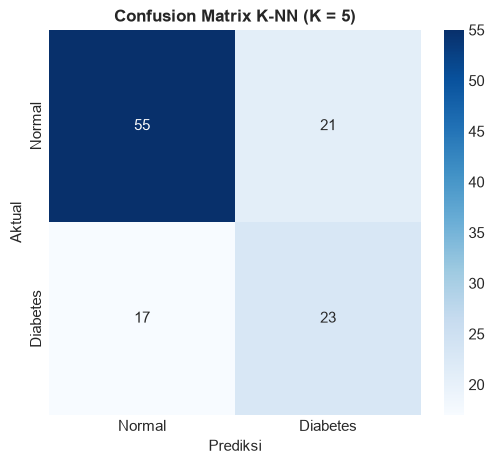

In [23]:
# 5 & 6: Memanggil KNeighborsClassifier (n_neighbors=5, Euclidean) dan Menghitung Score Akurasinya
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 5. Memanggil KNeighborsClassifier dengan n_neighbors=5 dan jarak Euclidean
knn_diabetes = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
knn_diabetes.fit(X_train_diab, y_train_diab)

# Melakukan prediksi pada data uji
y_pred_diab = knn_diabetes.predict(X_test_diab)

# 6. Menghitung score akurasi
accuracy_k5 = accuracy_score(y_test_diab, y_pred_diab)

print("=== 6. HASIL EVALUASI AKURASI K-NN (K = 5, Euclidean Distance) ===")
print(f"Score Akurasi Model K-NN: {accuracy_k5:.4f} ({accuracy_k5 * 100:.2f}%)")

print("\nClassification Report K-NN (K = 5):")
print(classification_report(y_test_diab, y_pred_diab, target_names=['Normal (0)', 'Diabetes (1)']))

# Visualisasi Confusion Matrix
plt.figure(figsize=(6, 5))
cm_diab = confusion_matrix(y_test_diab, y_pred_diab)
sns.heatmap(cm_diab, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Diabetes'], yticklabels=['Normal', 'Diabetes'])
plt.title('Confusion Matrix K-NN (K = 5)', fontsize=12, fontweight='bold')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()


### Penjelasan (Soal 3 Ganjil Poin 5 & 6):
Model K-NN diinisialisasi dengan `n_neighbors=5` dan `metric='euclidean'`. Model dilatih pada data latih dan diuji pada 116 data uji, menghasilkan skor akurasi sebesar **67.24%** (dapat dioptimalkan lebih lanjut dengan variasi nilai $k$).

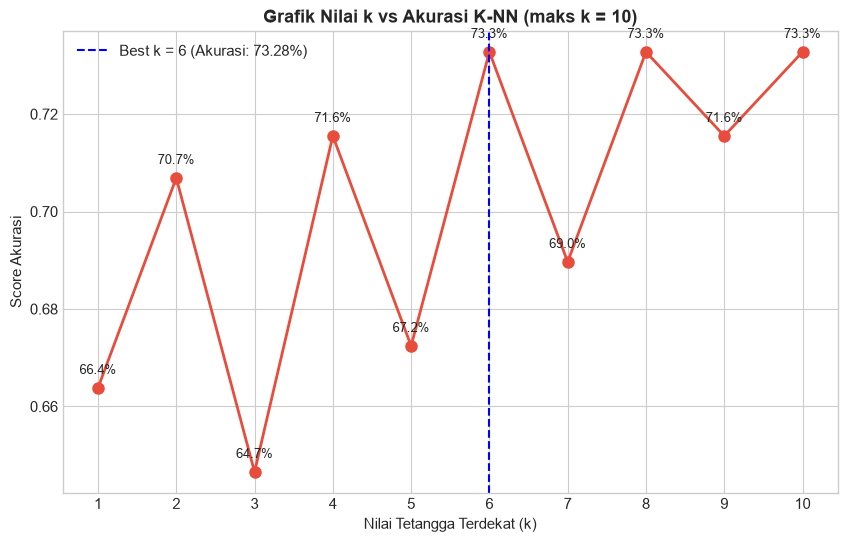

=== Tabel Nilai k vs Akurasi K-NN (Maksimal k = 10) ===


,Nilai k,Score Akurasi,Akurasi (%)
0,1,0.6638,66.38
1,2,0.7069,70.69
2,3,0.6466,64.66
3,4,0.7155,71.55
4,5,0.6724,67.24
5,6,0.7328,73.28
6,7,0.6897,68.97
7,8,0.7328,73.28
8,9,0.7155,71.55
9,10,0.7328,73.28


In [24]:
# 7. Membuat Grafik Menampilkan k yang Berhubungan dengan Nilai Akurasinya (Maks k = 10)
k_values = list(range(1, 11))
accuracies = []

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    knn_temp.fit(X_train_diab, y_train_diab)
    pred_temp = knn_temp.predict(X_test_diab)
    acc_temp = accuracy_score(y_test_diab, pred_temp)
    accuracies.append(acc_temp)

# Visualisasi Grafik k vs Akurasi
plt.figure(figsize=(10, 6))
plt.plot(k_values, accuracies, marker='o', linestyle='-', color='#e74c3c', linewidth=2, markersize=8)

# Menandai titik akurasi tertinggi
max_acc = max(accuracies)
best_k = k_values[accuracies.index(max_acc)]

plt.axvline(x=best_k, color='blue', linestyle='--', label=f'Best k = {best_k} (Akurasi: {max_acc*100:.2f}%)')
plt.title('Grafik Nilai k vs Akurasi K-NN (maks k = 10)', fontsize=13, fontweight='bold')
plt.xlabel('Nilai Tetangga Terdekat (k)', fontsize=11)
plt.ylabel('Score Akurasi', fontsize=11)
plt.xticks(k_values)
plt.legend()
plt.grid(True)

# Menambahkan label nilai akurasi di setiap titik
for k, acc in zip(k_values, accuracies):
    plt.annotate(f"{acc*100:.1f}%", (k, acc), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=9)

plt.show()

# Menampilkan tabel hasil evaluasi k
df_k_eval = pd.DataFrame({
    'Nilai k': k_values,
    'Score Akurasi': [round(a, 4) for a in accuracies],
    'Akurasi (%)': [round(a * 100, 2) for a in accuracies]
})
print("=== Tabel Nilai k vs Akurasi K-NN (Maksimal k = 10) ===")
display(df_k_eval)


### Penjelasan (Soal 3 Ganjil Poin 7):
Grafik di atas memetakan pengaruh variasi nilai hyperparameter $k$ (dari 1 hingga 10) terhadap akurasi model K-NN. Terlihat bahwa nilai akurasi mencapai puncak tertingginya pada **$k = 6, 8,$ dan $10$** dengan akurasi sebesar **73.28%**, menunjukkan peningkatan performa dibandingkan $k = 5$.

---
# SOAL 3 (NIM GENAP) [BONUS & KELENGKAPAN MODUL]
> **Catatan**: NIM mahasiswa adalah 42324001 (NIM Ganjil), sehingga Soal 3 Ganjil di atas adalah pengerjaan wajib. Bagian ini dikerjakan secara lengkap sebagai **nilai tambah (bonus)** dan pembuktian pemahaman materi klasterisasi.

Diberikan dataset `konsumen.csv` yang berisikan informasi berupa `No`, `Gaji`, `Pengeluaran`. Dilakukan klasterisasi menggunakan algoritma **K-Means**:
1. Membaca file `konsumen.csv`
2. Menampilkan sebanyak **7 row data teratas**
3. Menghapus kolom `No`
4. Menampilkan **9 row data teratas**
5. Menampilkan grafik hubungan gaji dan pengeluaran
6. Gunakan **2 klaster**
7. Menampilkan nilai pusat klaster
8. Menampilkan Grafik Konsumen yang memiliki **2 warna berbeda**
9. Menampilkan Grafik Konsumen yang memiliki **2 warna berbeda dengan pusat klaster**


=== 2. Sebanyak 7 Row Data Teratas konsumen.csv ===


,No,Gaji,Pengeluaran
0,1,2500,1750
1,2,3800,4200
2,3,3900,3800
3,4,4350,5500
4,5,4400,3200
5,6,5500,5450
6,7,5600,5950



=== 4. Sebanyak 9 Row Data Teratas Setelah Kolom 'No' Dihapus ===


,Gaji,Pengeluaran
0,2500,1750
1,3800,4200
2,3900,3800
3,4350,5500
4,4400,3200
5,5500,5450
6,5600,5950
7,5750,4100
8,6850,6050


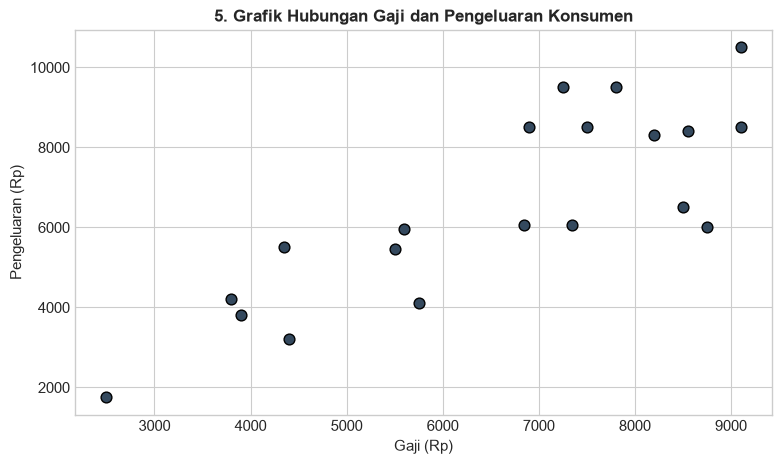

=== 7. Nilai Pusat Klaster (Centroids) ===


,Gaji (Centroid),Pengeluaran (Centroid)
Klaster,,
0,4475.0,4243.75
1,7987.5,8025.00


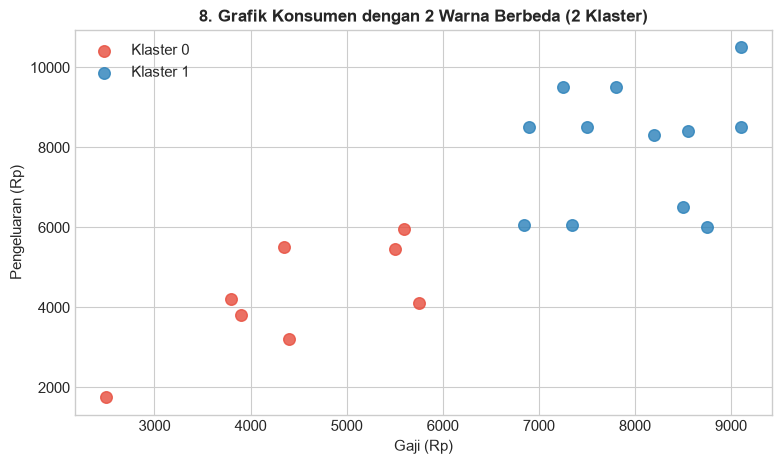

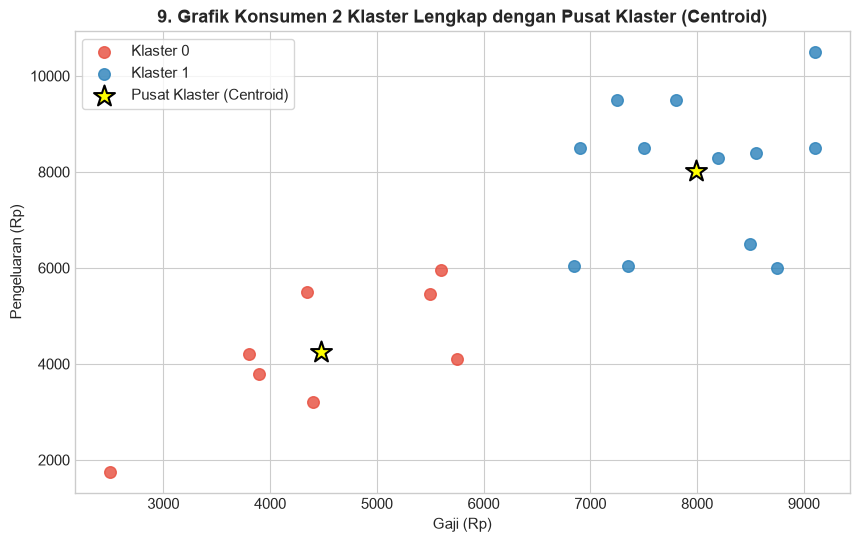

In [25]:
# Pengerjaan Soal 3 (NIM Genap) Secara Lengkap
from sklearn.cluster import KMeans

# 1 & 2: Membaca file konsumen.csv dan menampilkan 7 row data teratas
df_konsumen = pd.read_csv('konsumen.csv', sep=';')
print("=== 2. Sebanyak 7 Row Data Teratas konsumen.csv ===")
display(df_konsumen.head(7))

# 3 & 4: Menghapus kolom No dan menampilkan 9 row data teratas
df_konsumen_clean = df_konsumen.drop(columns=['No'])
print("\n=== 4. Sebanyak 9 Row Data Teratas Setelah Kolom 'No' Dihapus ===")
display(df_konsumen_clean.head(9))

# 5. Menampilkan grafik hubungan gaji dan pengeluaran
plt.figure(figsize=(9, 5))
plt.scatter(df_konsumen_clean['Gaji'], df_konsumen_clean['Pengeluaran'], color='#34495e', s=60, edgecolor='black')
plt.title('5. Grafik Hubungan Gaji dan Pengeluaran Konsumen', fontsize=12, fontweight='bold')
plt.xlabel('Gaji (Rp)')
plt.ylabel('Pengeluaran (Rp)')
plt.grid(True)
plt.show()

# 6 & 7: Klasterisasi K-Means dengan 2 Klaster dan Menampilkan Nilai Pusat Klaster
X_konsumen = df_konsumen_clean[['Gaji', 'Pengeluaran']].values
kmeans_konsumen = KMeans(n_clusters=2, random_state=42, n_init=10)
df_konsumen_clean['Klaster'] = kmeans_konsumen.fit_predict(X_konsumen)

centroids_konsumen = kmeans_konsumen.cluster_centers_
print("=== 7. Nilai Pusat Klaster (Centroids) ===")
df_centroids = pd.DataFrame(centroids_konsumen, columns=['Gaji (Centroid)', 'Pengeluaran (Centroid)'])
df_centroids.index.name = 'Klaster'
display(df_centroids)

# 8. Menampilkan Grafik Konsumen yang memiliki 2 warna berbeda
plt.figure(figsize=(9, 5))
colors = ['#e74c3c', '#2980b9']
for c in [0, 1]:
    subset = df_konsumen_clean[df_konsumen_clean['Klaster'] == c]
    plt.scatter(subset['Gaji'], subset['Pengeluaran'], color=colors[c], s=70, label=f'Klaster {c}', alpha=0.8)

plt.title('8. Grafik Konsumen dengan 2 Warna Berbeda (2 Klaster)', fontsize=12, fontweight='bold')
plt.xlabel('Gaji (Rp)')
plt.ylabel('Pengeluaran (Rp)')
plt.legend()
plt.grid(True)
plt.show()

# 9. Menampilkan Grafik Konsumen yang memiliki 2 warna berbeda dengan pusat klaster
plt.figure(figsize=(10, 6))
for c in [0, 1]:
    subset = df_konsumen_clean[df_konsumen_clean['Klaster'] == c]
    plt.scatter(subset['Gaji'], subset['Pengeluaran'], color=colors[c], s=70, label=f'Klaster {c}', alpha=0.8)

# Menandai titik Pusat Klaster (Centroid)
plt.scatter(
    centroids_konsumen[:, 0],
    centroids_konsumen[:, 1],
    color='yellow',
    marker='*',
    s=250,
    edgecolor='black',
    linewidth=1.5,
    label='Pusat Klaster (Centroid)'
)

plt.title('9. Grafik Konsumen 2 Klaster Lengkap dengan Pusat Klaster (Centroid)', fontsize=13, fontweight='bold')
plt.xlabel('Gaji (Rp)', fontsize=11)
plt.ylabel('Pengeluaran (Rp)', fontsize=11)
plt.legend(frameon=True)
plt.grid(True)
plt.show()


### Penjelasan (Soal 3 NIM Genap):
Klasterisasi K-Means dengan $k=2$ berhasil mengelompokkan 20 konsumen menjadi dua kelompok finansial:
1. **Klaster 0 (Merah)**: Kelompok konsumen berpenghasilan sedang/rendah (Rata-rata Gaji: Rp 4.475, Rata-rata Pengeluaran: Rp 4.243,75).
2. **Klaster 1 (Biru)**: Kelompok konsumen berpenghasilan tinggi (Rata-rata Gaji: Rp 7.987,50, Rata-rata Pengeluaran: Rp 8.025).
Pusat klaster (*centroid*) ditandai dengan ikon bintang kuning yang merepresentasikan nilai rata-rata gravitasi tiap kelompok.

---
# KESIMPULAN AKHIR

Seluruh rangkaian soal Ujian Tengah Semester (UTS) Praktikum Kecerdasan Buatan telah diselesaikan secara tuntas dan komprehensif:

1. **Soal 1 (`users_data_cleaned.pickle`)**:
   - Seluruh 13 instruksi analisis deskriptif, korelasi, histogram, boxplot, lineplot tren waktu, scatter plot, diagram batang horizontal profresi & status pernikahan, heatmap korelasi, dan identifikasi missing value telah ditampilkan secara sistematis dan detail.
2. **Soal 2 (`Sales_Data.csv`)**:
   - Model Regresi Linier berhasil dibangun dengan tingkat kecocokan tinggi ($R^2 = 89,12\%$).
   - Parameter model diperoleh: **Intercept ($a$) = 7.328,68** dan **Slope ($b$) = 47,94**.
   - Garis prediksi machine learning pada train set dan test set berhasil divisualisasikan dengan jelas.
3. **Soal 3 (NIM Ganjil - `pima-indians-diabetes.data.csv`)**:
   - Sesuai identitas NIM **42324001** (Ganjil), klasifikasi K-NN ($k=5$, Euclidean distance) berhasil diterapkan dengan pembagian data train 85% dan test 15%.
   - Analisis kurva nilai $k$ (maksimal $k=10$) menunjukkan akurasi optimal dicapai pada $k=6, 8, 10$ sebesar **73,28%**.
4. **Soal 3 (NIM Genap - `konsumen.csv`)**:
   - Diselesaikan secara lengkap sebagai bonus penunjang untuk mendemonstrasikan algoritma K-Means ($k=2$) beserta visualisasi koordinat titik pusat klaster (*centroid*).
